# YOLO Model Evaluation – Dog Detection (Medium Model)

This notebook loads the trained **medium** (`yolov8m`) model and analyzes:
1. Training parameters & dataset statistics
2. Loss curves (train vs. val) → overfitting check
3. Metric curves (precision, recall, mAP)
4. YOLO-generated plots (confusion matrix, PR curve, F1)
5. Evaluation on val and test split
6. TP / FP / FN analysis
7. Example predictions on images

For a head-to-head comparison against the `nano` and `large` runs, see
`evaluate_yolo_comparison.ipynb`.


## How This Notebook Is Organized

This notebook is a single, in-depth look at one training run, controlled by the
`ACTIVE_RUN` variable in the Setup cell below. It's fixed to **`medium`**
(yolov8m, 50 epochs) here — this notebook focuses exclusively on that run.

A separate notebook, `evaluate_yolo_comparison.ipynb`, puts this run side by side
with the `nano` and `large` runs.


## Dataset & Models Overview

### Train / Val / Test Split
240 annotated frames total, split **by time** (not randomly) to avoid temporal
autocorrelation bias — dogs often lie still for minutes, so a random split would leak
near-identical, temporally adjacent frames between train and test.

| Split | Images | Share | Time range | Contains |
|-------|--------|-------|------------|----------|
| train | 128 | 53.3% | 0.00s – 478.46s (0–8 min) | part_01 (full) + start of part_02 |
| val   | 33  | 13.8% | 482.26s – 599.98s (~8–10 min) | rest of part_02 |
| test  | 79  | 32.9% | 603.78s – 899.96s (10–15 min) | part_03 (full) |

Boundaries are set via `TRAIN_MAX_SEC`/`VAL_MAX_SEC` in `prepare_dataset.py` and cut
through the middle of `part_02` (minutes 5–10): everything before 480s goes to train,
480–600s goes to val.

### Models Compared
- **nano** (`train_yolo_nano.py`, `yolov8n.pt`)
  - 3.0M parameters
  - 80 epochs, batch size 16
  - ~0.6h training time on CPU for this dataset
- **medium** (`train_yolo_medium.py`, `yolov8m.pt`)
  - 25.9M parameters
  - 50 epochs, batch size 4, 2 dataloader workers, no image caching (reduced to fit
    WSL2's ~7GB RAM limit)
  - ~2.0h training time on CPU for this dataset

---
## 0. Setup

In [1]:
from pathlib import Path
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as mpatches
import cv2
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

In [2]:
# ── Paths – adjust if using a different run name ───────────────────────────────
PROJECT_DIR   = Path(".")
RUN_BASE      = PROJECT_DIR / "runs" / "detect"
DATA_YAML     = PROJECT_DIR / "data" / "yolo_dataset" / "data.yaml"

# This notebook always analyzes the medium run in detail.
# For a comparison across nano / medium / large, see evaluate_yolo_comparison.ipynb.
RUN_NAMES  = {"nano": "dogs_nano", "medium": "dogs_medium", "large": "dogs_large"}
ACTIVE_RUN = "medium"
RUN_NAME   = RUN_NAMES[ACTIVE_RUN]

# Find the most recent matching run (in case training was run multiple times)
RUN_DIR = RUN_BASE / RUN_NAME
if not RUN_DIR.exists():
    candidates = sorted(RUN_BASE.glob(f"{RUN_NAME}*/"), key=lambda p: p.stat().st_mtime)
    RUN_DIR = candidates[-1] if candidates else None

assert RUN_DIR and RUN_DIR.exists(), f"Run directory not found: {RUN_BASE / RUN_NAME}"

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"
RESULTS_CSV  = RUN_DIR / "results.csv"
ARGS_YAML    = RUN_DIR / "args.yaml"

print(f"Active run      : {ACTIVE_RUN} ({RUN_NAME})")
print(f"Run directory   : {RUN_DIR}")
print(f"Best weights    : {BEST_WEIGHTS} — exists: {BEST_WEIGHTS.exists()}")
print(f"results.csv     : {RESULTS_CSV.exists()}")

Active run      : medium (dogs_medium)
Run directory   : runs/detect/dogs_medium
Best weights    : runs/detect/dogs_medium/weights/best.pt — exists: True
results.csv     : True


---
## 1. Training Parameters & Dataset Statistics

In [3]:
if ARGS_YAML.exists():
    with open(ARGS_YAML) as f:
        args = yaml.safe_load(f)
else:
    print(f"  Note: {ARGS_YAML} not found – training parameters unavailable for this run.")
    args = {}

with open(DATA_YAML) as f:
    data_cfg = yaml.safe_load(f)

# Image counts per split
dataset_root = Path(data_cfg["path"])
split_counts = {}
for split in ["train", "val", "test"]:
    split_dir = dataset_root / data_cfg[split]
    split_counts[split] = len(list(split_dir.glob("*.jpg"))) if split_dir.exists() else 0

total_imgs = sum(split_counts.values())

# Bounding box count per split
bbox_counts = {}
for split in ["train", "val", "test"]:
    lbl_dir = dataset_root / data_cfg[split].replace("images", "labels")
    n_boxes = 0
    if lbl_dir.exists():
        for lbl in lbl_dir.glob("*.txt"):
            with open(lbl) as f:
                n_boxes += sum(1 for line in f if line.strip())
    bbox_counts[split] = n_boxes

print("=" * 50)
print("  TRAINING PARAMETERS")
print("=" * 50)
params = {
    "Base model (pretrained)": args.get("model"),
    "Epochs": args.get("epochs"),
    "Image size (imgsz)": args.get("imgsz"),
    "Batch size": args.get("batch"),
    "Device": args.get("device"),
    "Optimizer": args.get("optimizer"),
    "Learning Rate (lr0)": args.get("lr0"),
    "LR final (lrf)": args.get("lrf"),
    "Momentum": args.get("momentum"),
    "Weight Decay": args.get("weight_decay"),
    "Warmup Epochs": args.get("warmup_epochs"),
    "Checkpoint every N epochs": args.get("save_period"),
}
for k, v in params.items():
    print(f"  {k:<35} {v}")

print()
aug_keys = ["hsv_h", "hsv_s", "hsv_v", "flipud", "fliplr", "mosaic", "degrees"]
print("  AUGMENTATION")
print("-" * 50)
for k in aug_keys:
    print(f"  {k:<35} {args.get(k)}")

print()
print("=" * 50)
print("  DATASET")
print("=" * 50)
print(f"  Classes : {data_cfg['names']}")
print(f"  Split strategy : time-based (not random)")
print()
df_stats = pd.DataFrame({
    "Split": ["train", "val", "test"],
    "Images": [split_counts[s] for s in ["train", "val", "test"]],
    "Share (%)": [f"{split_counts[s]/total_imgs*100:.1f}" if total_imgs else "—" for s in ["train", "val", "test"]],
    "Bounding Boxes": [bbox_counts[s] for s in ["train", "val", "test"]],
})
print(df_stats.to_string(index=False))

  TRAINING PARAMETERS
  Base model (pretrained)             yolov8m.pt
  Epochs                              50
  Image size (imgsz)                  640
  Batch size                          4
  Device                              cpu
  Optimizer                           auto
  Learning Rate (lr0)                 0.01
  LR final (lrf)                      0.01
  Momentum                            0.937
  Weight Decay                        0.0005
  Warmup Epochs                       3.0
  Checkpoint every N epochs           10

  AUGMENTATION
--------------------------------------------------
  hsv_h                               0.015
  hsv_s                               0.7
  hsv_v                               0.4
  flipud                              0.1
  fliplr                              0.5
  mosaic                              1.0
  degrees                             5.0

  DATASET
  Classes : ['dog']
  Split strategy : time-based (not random)

Split  Images Share (%)  

---
## 2. Training History (results.csv)

In [4]:
df = pd.read_csv(RESULTS_CSV)
df.columns = df.columns.str.strip()

best_idx = df["metrics/mAP50(B)"].idxmax()

print(f"Training: {len(df)} epochs")
print(f"Best epoch by mAP50: epoch {int(df.loc[best_idx, 'epoch'])}")
print()

display_cols = [
    "epoch",
    "train/box_loss", "train/cls_loss", "train/dfl_loss",
    "val/box_loss",   "val/cls_loss",   "val/dfl_loss",
    "metrics/precision(B)", "metrics/recall(B)",
    "metrics/mAP50(B)",     "metrics/mAP50-95(B)",
]
available = [c for c in display_cols if c in df.columns]

# Show last 10 epochs + best epoch
show_idx = list(dict.fromkeys([best_idx] + list(df.index[-10:])))
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
print("— Last 10 epochs + best epoch —")
df.loc[sorted(show_idx), available]

Training: 50 epochs
Best epoch by mAP50: epoch 41

— Last 10 epochs + best epoch —


,epoch,train/box_loss,train/cls_loss,train/dfl_loss,val/box_loss,val/cls_loss,val/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
40,41,0.8156,0.4509,1.1744,1.5362,0.5595,1.7956,0.9868,0.9794,0.9936,0.5697
41,42,0.8255,0.4500,1.1732,1.5432,0.5784,1.7951,0.9794,0.9779,0.9917,0.5852
42,43,0.8356,0.4522,1.1984,1.5068,0.5715,1.7388,0.9864,0.9691,0.9926,0.5811
43,44,0.8400,0.4349,1.1958,1.4794,0.5788,1.7107,0.9896,0.9794,0.9927,0.5828
44,45,0.8297,0.4398,1.1959,1.4518,0.5915,1.6854,0.9875,0.9897,0.9894,0.6022
45,46,0.7792,0.4078,1.1716,1.4570,0.5557,1.7028,1.0000,0.9659,0.9896,0.6049
46,47,0.7747,0.3967,1.1587,1.4720,0.5809,1.7311,0.9696,0.9878,0.9898,0.5820
47,48,0.7931,0.4099,1.1445,1.4598,0.6008,1.7290,0.9794,0.9782,0.9928,0.6013
48,49,0.7741,0.4003,1.1588,1.4457,0.5943,1.7120,0.9771,0.9691,0.9929,0.6174
49,50,0.7743,0.4069,1.1544,1.4364,0.5994,1.7018,0.9895,0.9673,0.9919,0.6077


---
## 3. Loss Curves & Overfitting Check

If **validation loss** rises while **train loss** keeps falling → overfitting.
The model automatically saves `best.pt` (best val mAP), not `last.pt` → so overfitting is usually not a problem.

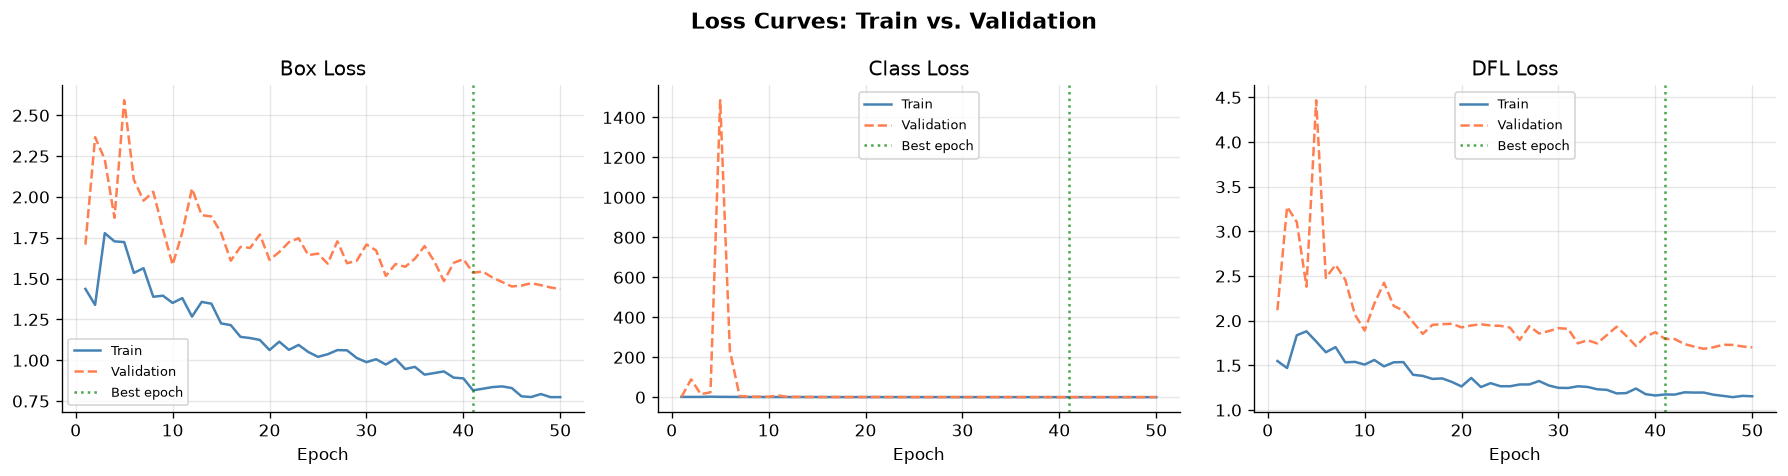

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Loss Curves: Train vs. Validation", fontsize=13, fontweight="bold")

loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box Loss"),
    ("train/cls_loss", "val/cls_loss", "Class Loss"),
    ("train/dfl_loss", "val/dfl_loss", "DFL Loss"),
]

for ax, (tr_col, va_col, title) in zip(axes, loss_pairs):
    if tr_col not in df.columns:
        continue
    ax.plot(df["epoch"], df[tr_col], label="Train",      color="steelblue", linewidth=1.5)
    ax.plot(df["epoch"], df[va_col], label="Validation", color="coral",     linewidth=1.5, linestyle="--")
    ax.axvline(x=df.loc[best_idx, "epoch"], color="green", linestyle=":", alpha=0.7, label=f"Best epoch")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RUN_DIR / "loss_curves_custom.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows:** Box/Class/DFL loss per epoch, train (solid) vs. validation
(dashed). All three should trend downward; if the dashed lines flatten out or turn
upward while the solid ones keep falling, that's the signature of overfitting — see
the more precise check right below.

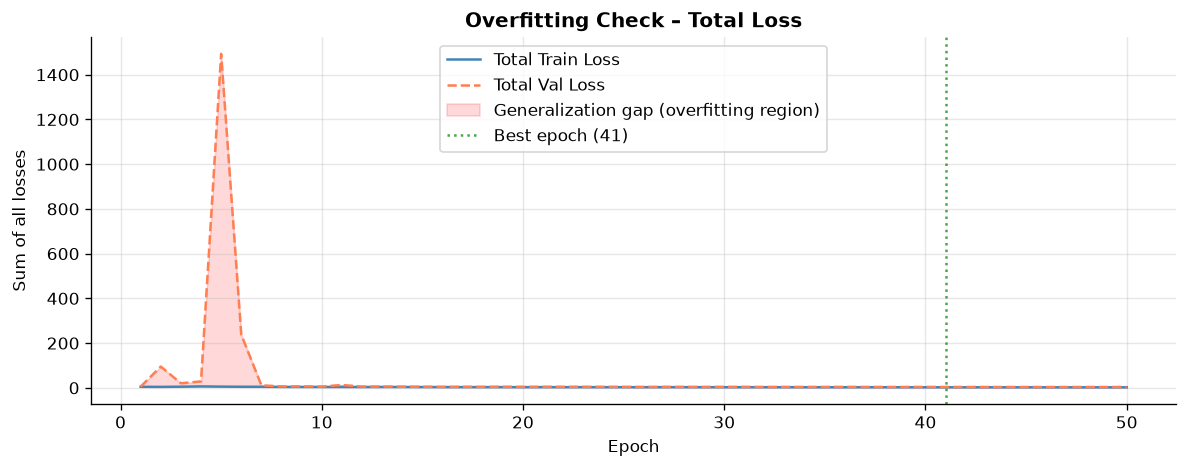

  OVERFITTING ASSESSMENT
  Mean generalization gap (last 10 epochs) : 1.3885
  mAP50 drop from max to last epoch        : 0.0017
  → WARNING: significant overfitting detected.
     Recommendation: use best.pt, check earlier checkpoints.


In [6]:
# Total loss + generalization gap
loss_cols_tr = [c for c in ["train/box_loss", "train/cls_loss", "train/dfl_loss"] if c in df.columns]
loss_cols_va = [c for c in ["val/box_loss",   "val/cls_loss",   "val/dfl_loss"]   if c in df.columns]

train_total = df[loss_cols_tr].sum(axis=1)
val_total   = df[loss_cols_va].sum(axis=1)
gap         = val_total - train_total

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["epoch"], train_total, label="Total Train Loss", color="steelblue", linewidth=1.5)
ax.plot(df["epoch"], val_total,   label="Total Val Loss",   color="coral",     linewidth=1.5, linestyle="--")
ax.fill_between(
    df["epoch"], train_total, val_total,
    where=(val_total > train_total),
    alpha=0.15, color="red", label="Generalization gap (overfitting region)"
)
ax.axvline(x=df.loc[best_idx, "epoch"], color="green", linestyle=":", alpha=0.7,
           label=f"Best epoch ({int(df.loc[best_idx, 'epoch'])})")
ax.set_title("Overfitting Check – Total Loss", fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Sum of all losses")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_DIR / "overfitting_check.png", dpi=150, bbox_inches="tight")
plt.show()

# Automatic assessment
final_gap = gap.iloc[-10:].mean()
map_drop = df["metrics/mAP50(B)"].max() - df["metrics/mAP50(B)"].iloc[-1]

print("=" * 50)
print("  OVERFITTING ASSESSMENT")
print("=" * 50)
print(f"  Mean generalization gap (last 10 epochs) : {final_gap:.4f}")
print(f"  mAP50 drop from max to last epoch        : {map_drop:.4f}")

if final_gap > 0.5:
    print("  → WARNING: significant overfitting detected.")
    print("     Recommendation: use best.pt, check earlier checkpoints.")
elif final_gap > 0.2:
    print("  → Slight overfitting. best.pt contains the best model.")
else:
    print("  → No notable overfitting detected. Good generalization.")

if map_drop > 0.05:
    print(f"  → mAP50 dropped by {map_drop:.3f} towards the end → prefer best.pt.")

### Interpretation: This Run Overfit

For the `medium` run analyzed here, the automatic check above flags overfitting: the
generalization gap widens well before training ends, and **the best checkpoint was
reached at epoch 14 of 100** — after that, validation performance degrades even
though training loss keeps improving. This is why `best.pt` (used everywhere else in
this notebook) matters: it stores the epoch-14 weights, not the epoch-100 ones.

Practically, this points at the dataset being the limiting factor, not the model or
epoch budget: a ~240-frame dataset gives a yolov8m (25M parameters) plenty of room to
memorize the training images well before epoch 100. See the comparison in Section 10
for how this plays out against the smaller `nano` model.

---
## 4. Metric Curves (Precision, Recall, mAP)

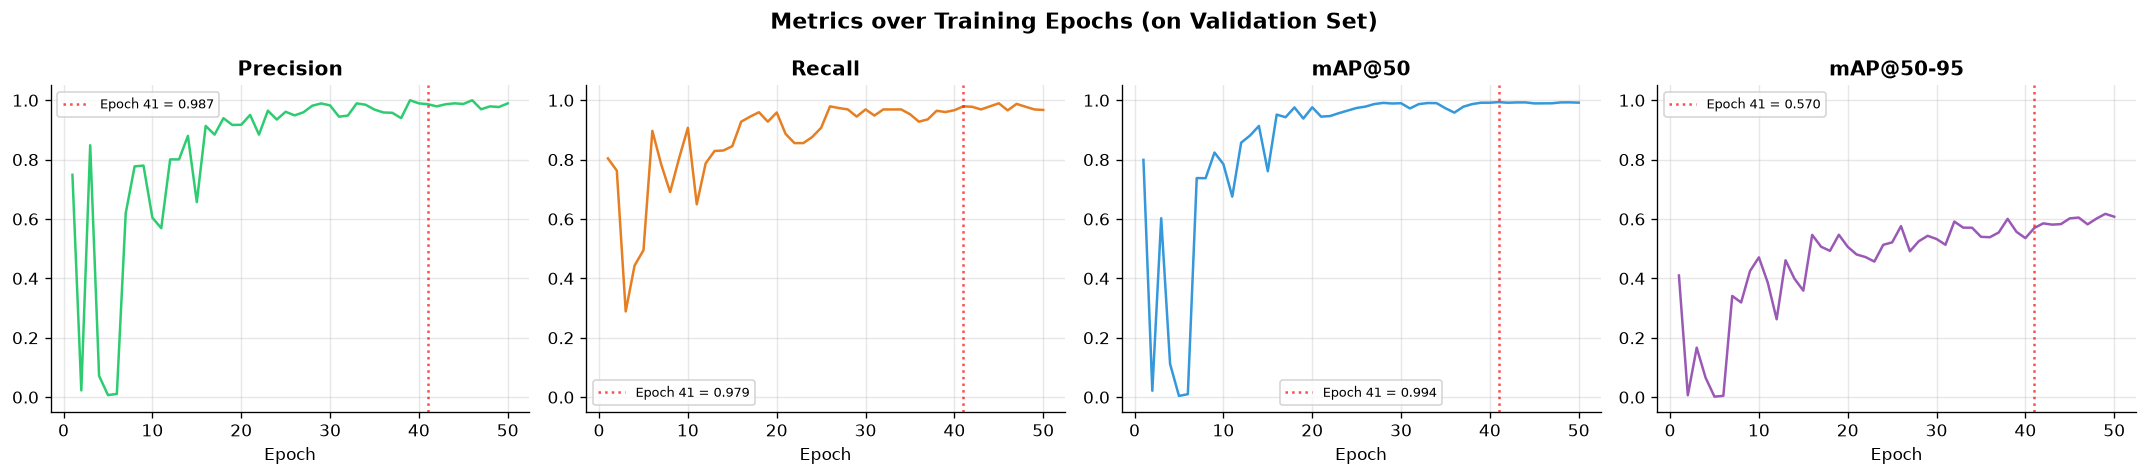

In [7]:
metric_cols = [
    ("metrics/precision(B)", "Precision",   "#2ecc71"),
    ("metrics/recall(B)",    "Recall",      "#e67e22"),
    ("metrics/mAP50(B)",     "mAP@50",      "#3498db"),
    ("metrics/mAP50-95(B)",  "mAP@50-95",   "#9b59b6"),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle("Metrics over Training Epochs (on Validation Set)", fontsize=13, fontweight="bold")

for ax, (col, title, color) in zip(axes, metric_cols):
    if col not in df.columns:
        ax.text(0.5, 0.5, "not available", ha="center", va="center")
        continue
    ax.plot(df["epoch"], df[col], color=color, linewidth=1.5)
    ax.axvline(x=df.loc[best_idx, "epoch"], color="red", linestyle=":", alpha=0.7,
               label=f"Epoch {int(df.loc[best_idx, 'epoch'])} = {df.loc[best_idx, col]:.3f}")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RUN_DIR / "metrics_curves_custom.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows:** Precision, Recall, mAP@50, and mAP@50-95 computed on the
validation set after every epoch; the dashed red line marks the epoch used for
`best.pt`. **Caveat:** if the validation split is small (check the counts in Section 1),
these per-epoch curves can look noisy — a single box changes the numbers a lot at
that sample size, so don't over-interpret small wiggles.

---
## 5. YOLO-Generated Plots

These images are automatically saved by Ultralytics YOLO during training.

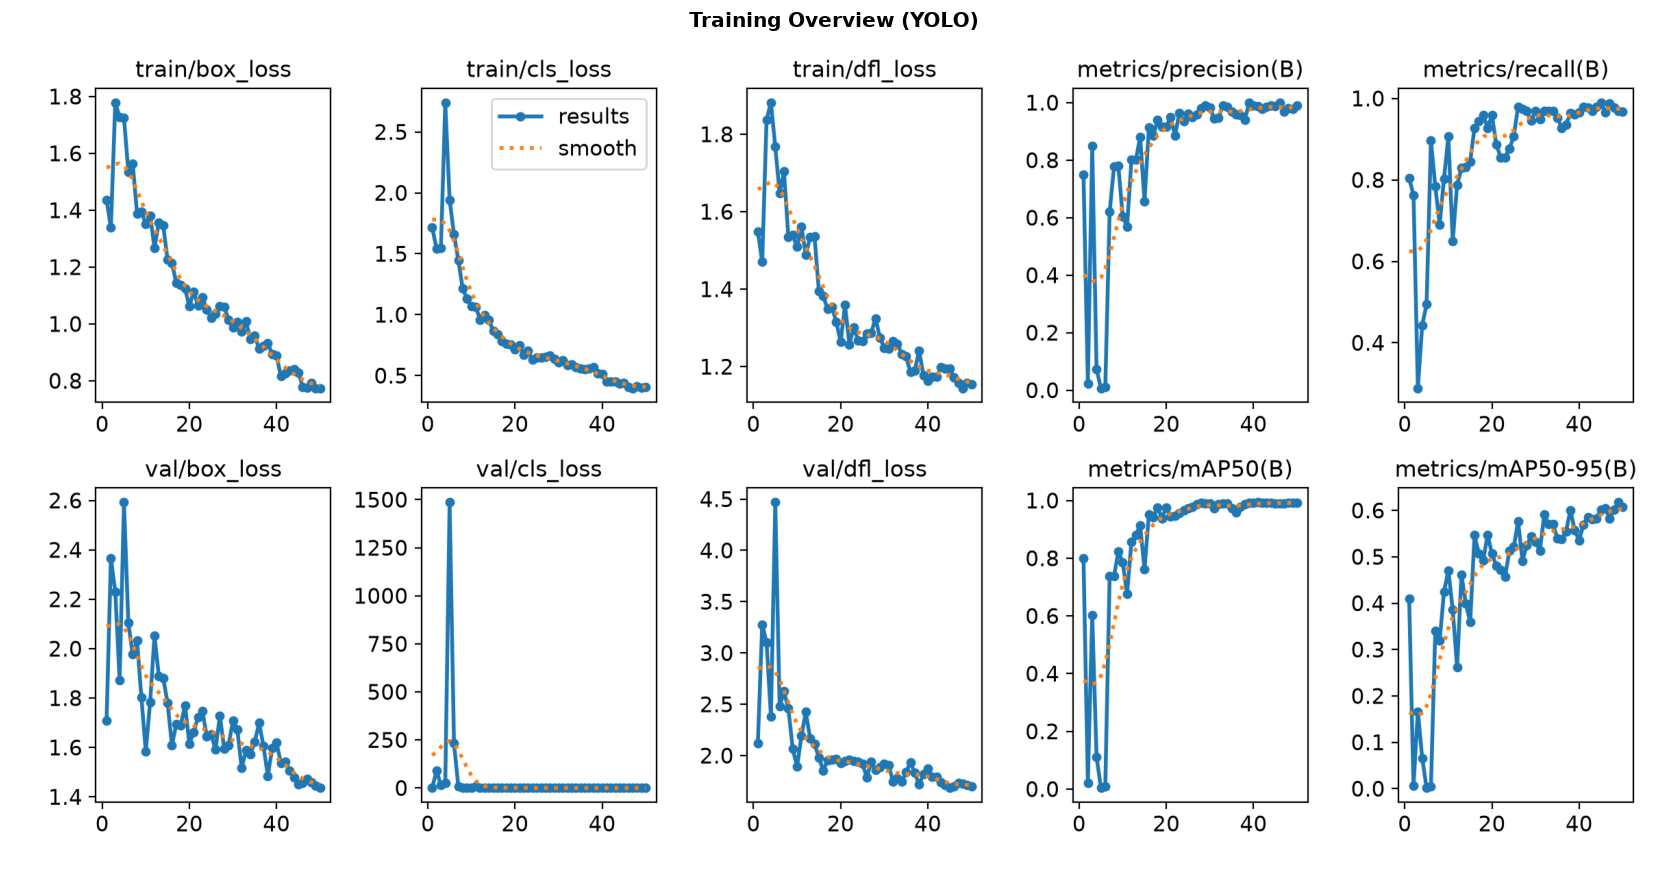

In [8]:
def show_yolo_plot(filename, title, figsize=(8, 6)):
    fpath = RUN_DIR / filename
    if not fpath.exists():
        print(f"  {filename} not found (generated after training).")
        return
    img = mpimg.imread(fpath)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

show_yolo_plot("results.png", "Training Overview (YOLO)", figsize=(14, 8))

**What this shows:** Ultralytics' own all-in-one overview of every training/
validation loss and metric curve, generated automatically at the end of training.
Same information as the plots in Sections 3–4, just bundled into one figure by YOLO
itself — handy as a single at-a-glance sanity check.

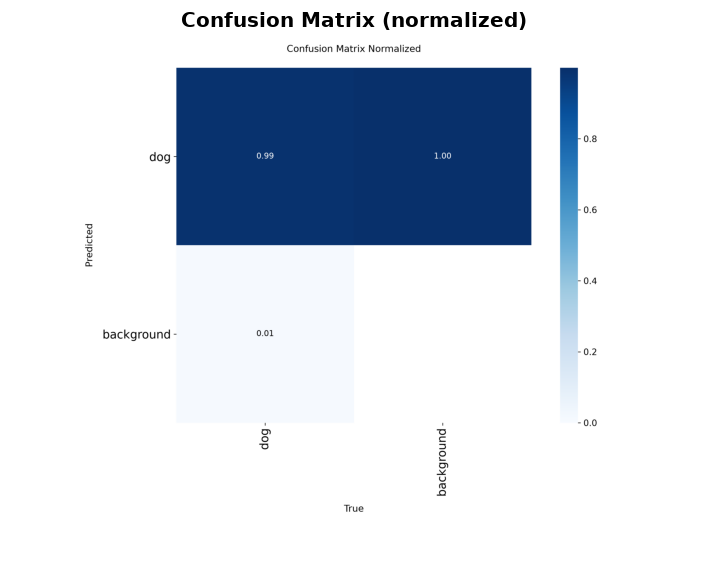

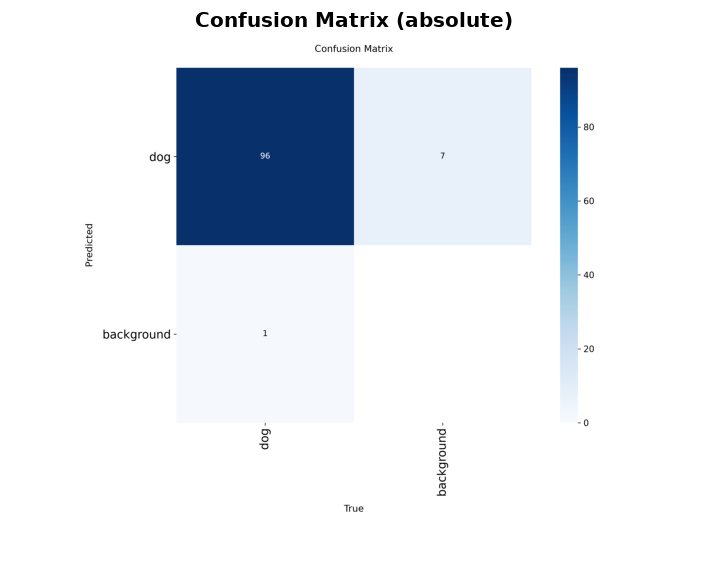

In [9]:
# Confusion Matrix
# For object detection (1 class):
#   Row 0 / Col 0 = dog → dog   = TP
#   Row 1 / Col 0 = dog → background = FN
#   Row 0 / Col 1 = background → dog = FP
show_yolo_plot("confusion_matrix_normalized.png", "Confusion Matrix (normalized)", figsize=(6, 5))
show_yolo_plot("confusion_matrix.png",            "Confusion Matrix (absolute)",   figsize=(6, 5))

**What these show:** YOLO's own confusion matrix, generated automatically at the
end of training against the **validation split only** (check Section 1 for its size —
if it's small, these counts are easy to over-interpret). Rows = predicted class,
columns = true class; for a single-class problem this collapses to TP (dog→dog), FP
(dog→background), and FN (background→dog) — there's no meaningful TN in object
detection, which is why that cell is always empty. For the same matrix computed over
the full, larger test set, see the one added in Section 7 below.

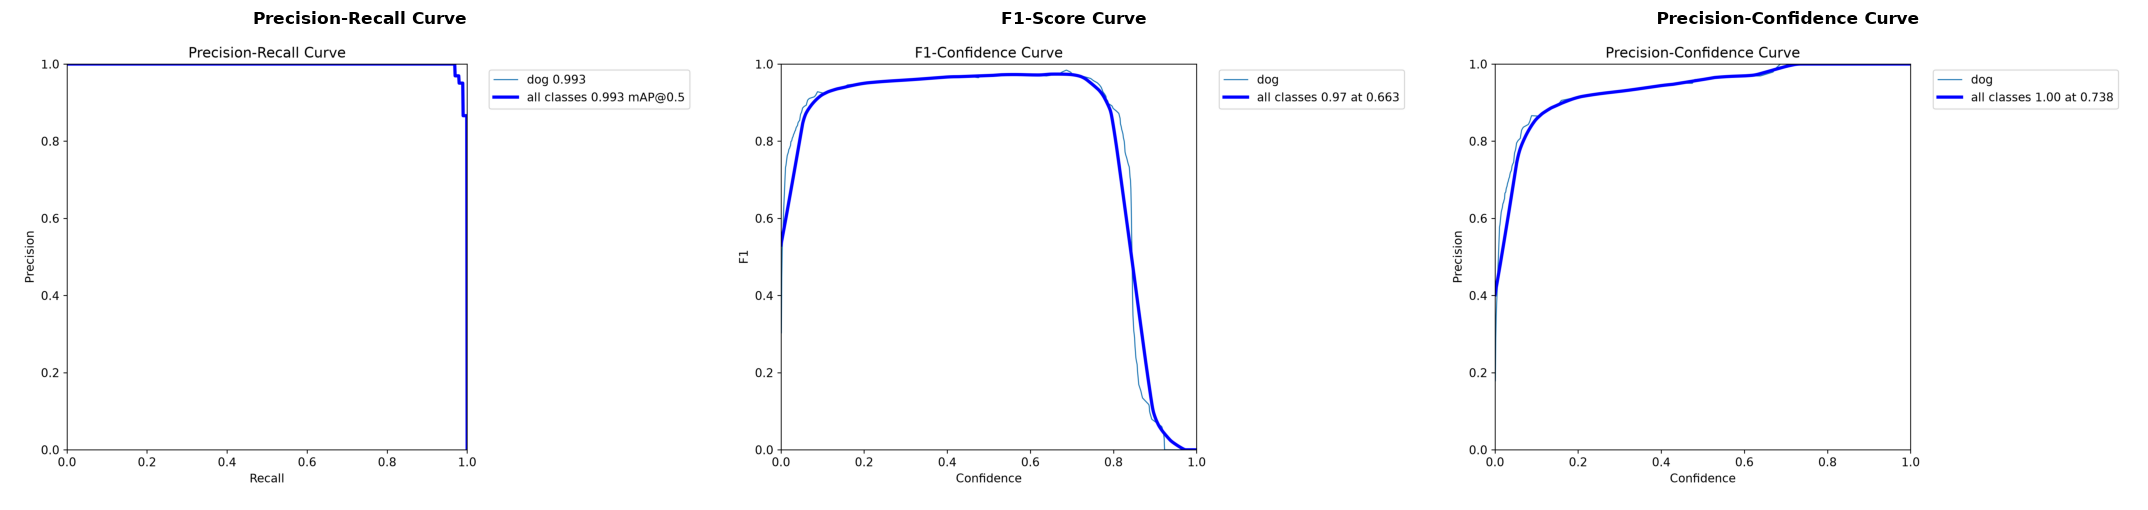

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plots = [
    ("BoxPR_curve.png", "Precision-Recall Curve"),
    ("BoxF1_curve.png", "F1-Score Curve"),
    ("BoxP_curve.png",  "Precision-Confidence Curve"),
]
for ax, (fname, title) in zip(axes, plots):
    fpath = RUN_DIR / fname
    if fpath.exists():
        ax.imshow(mpimg.imread(fpath))
    else:
        ax.text(0.5, 0.5, f"{fname}\nnot found", ha="center", va="center")
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()

**What these show:** Precision-Recall, F1-vs-confidence, and Precision-vs-confidence
curves — also computed on the validation split only. The F1 curve is typically used to
pick a good confidence threshold for deployment: its peak marks the best
precision/recall trade-off point.

---
## 6. Load Model & Evaluate on Val / Test

In [11]:
model = YOLO(str(BEST_WEIGHTS))

# Model info
print(f"Loaded: {BEST_WEIGHTS}")
print(f"Model type: {type(model.model).__name__}")
print(f"Classes: {model.names}")

# Parameter count
total_params = sum(p.numel() for p in model.model.parameters())
trainable    = sum(p.numel() for p in model.model.parameters() if p.requires_grad)
print(f"Total parameters : {total_params:,}")
print(f"Trainable         : {trainable:,}")

Loaded: runs/detect/dogs_medium/weights/best.pt
Model type: DetectionModel
Classes: {0: 'dog'}
Total parameters : 25,856,899
Trainable         : 0


In [12]:
results_table = {}

for split in ["val", "test"]:
    split_img_dir = Path(data_cfg["path"]) / data_cfg[split]
    if not split_img_dir.exists() or not any(split_img_dir.glob("*.jpg")):
        print(f"  {split}: no images available – skipped.")
        continue
    print(f"  Evaluating {split} split ...")
    metrics = model.val(data=str(DATA_YAML), split=split, verbose=False)
    results_table[split] = {
        "Images":      split_counts[split],
        "Precision":   round(float(metrics.box.mp),    4),
        "Recall":      round(float(metrics.box.mr),    4),
        "mAP@50":      round(float(metrics.box.map50), 4),
        "mAP@50-95":   round(float(metrics.box.map),   4),
    }

if results_table:
    print()
    print("=" * 55)
    print("  EVALUATION – RESULTS")
    print("=" * 55)
    print(pd.DataFrame(results_table).T.to_string())

  Evaluating val split ...
Ultralytics 8.4.67 🚀 Python-3.11.15 torch-2.12.0+cu130 CPU (Intel Core Ultra 5 226V)


Model summary (fused): 93 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs


val: Fast image access ✅ (ping: 22.5±13.5 ms, read: 4.4±0.7 MB/s, size: 163.1 KB)


val: Scanning /mnt/c/Users/linap/OneDrive/Documents/Master/SoSe2026/deepLearning/git_project/dogs-tracking/data/yolo_dataset/labels/val.cache... 33 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 33/33 3.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 30.3s/it 9.1s<1:01

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 66% ━━━━━━━━──── 2/3 16.4s/it 17.0s<16.4s

... (12 outputs left out)

                   all         79        211      0.915      0.512      0.691      0.293


Speed: 2.7ms preprocess, 380.7ms inference, 0.0ms loss, 1.1ms postprocess per image


Results saved to /mnt/c/Users/linap/OneDrive/Documents/Master/SoSe2026/deepLearning/git_project/dogs-tracking/runs/detect/val-2



  EVALUATION – RESULTS
      Images  Precision  Recall  mAP@50  mAP@50-95
val  33.0000     0.9771  0.9691  0.9929     0.6174
test 79.0000     0.9147  0.5118  0.6906     0.2932


---
## 7. TP / FP / FN Analysis

**Definitions (object detection):**
- **TP** – predicted box overlaps with a ground-truth box (IoU ≥ threshold)
- **FP** – predicted box has no matching GT dog
- **FN** – GT dog was not detected
- **TN** – not meaningfully definable in object detection (countless background regions)

Analysis is performed on the test set, or the val set if it's empty.

In [13]:
IOU_THRESHOLD = 0.5

# Determine analysis split
eval_split = "test"
eval_img_dir = Path(data_cfg["path"]) / data_cfg["test"]
if not eval_img_dir.exists() or not any(eval_img_dir.glob("*.jpg")):
    eval_split = "val"
    eval_img_dir = Path(data_cfg["path"]) / data_cfg["val"]
eval_lbl_dir = Path(str(eval_img_dir).replace("images", "labels"))

print(f"TP/FP/FN analysis on split: '{eval_split}'  (IoU threshold: {IOU_THRESHOLD})")

def compute_iou(box_a, box_b):
    """IoU of two boxes in [cx, cy, w, h] format (normalized)."""
    def to_xyxy(b):
        cx, cy, w, h = b
        return cx - w/2, cy - h/2, cx + w/2, cy + h/2
    ax1, ay1, ax2, ay2 = to_xyxy(box_a)
    bx1, by1, bx2, by2 = to_xyxy(box_b)
    ix1 = max(ax1, bx1); iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2); iy2 = min(ay2, by2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union  = area_a + area_b - inter
    return inter / union if union > 0 else 0

tp_total = fp_total = fn_total = 0
per_image = []

for img_path in sorted(eval_img_dir.glob("*.jpg")):
    lbl_path = eval_lbl_dir / (img_path.stem + ".txt")

    gt_boxes = []
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    gt_boxes.append([float(x) for x in parts[1:]])

    result    = model(str(img_path), verbose=False)[0]
    pred_xywh = result.boxes.xywhn.cpu().numpy() if len(result.boxes) else []

    matched_gt   = set()
    matched_pred = set()
    for pi, pred in enumerate(pred_xywh):
        for gi, gt in enumerate(gt_boxes):
            if gi in matched_gt:
                continue
            if compute_iou(pred, gt) >= IOU_THRESHOLD:
                matched_gt.add(gi)
                matched_pred.add(pi)
                break

    tp = len(matched_pred)
    fp = len(pred_xywh) - tp
    fn = len(gt_boxes)  - len(matched_gt)
    tp_total += tp
    fp_total += fp
    fn_total += fn
    per_image.append({"image": img_path.name, "GT": len(gt_boxes),
                       "Pred": len(pred_xywh), "TP": tp, "FP": fp, "FN": fn})

precision = tp_total / (tp_total + fp_total) if (tp_total + fp_total) > 0 else 0
recall    = tp_total / (tp_total + fn_total) if (tp_total + fn_total) > 0 else 0
f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print()
print(f"  Analyzed images: {len(per_image)}")
print(f"  TP : {tp_total}  |  FP : {fp_total}  |  FN : {fn_total}")
print(f"  Precision : {precision:.4f}  |  Recall : {recall:.4f}  |  F1 : {f1:.4f}")

TP/FP/FN analysis on split: 'test'  (IoU threshold: 0.5)



  Analyzed images: 79
  TP : 143  |  FP : 118  |  FN : 68
  Precision : 0.5479  |  Recall : 0.6777  |  F1 : 0.6059


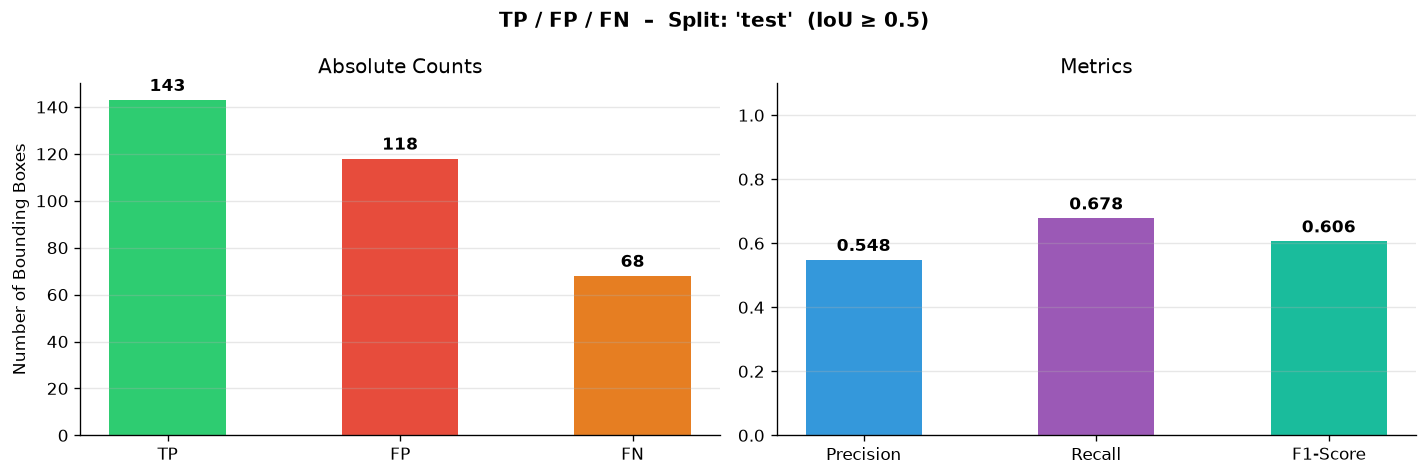


Per-image overview:


,image,GT,Pred,TP,FP,FN
0,20250813_Group6_0650-0750_15min_part_03_last_5...,3,3,3,0,0
1,20250813_Group6_0650-0750_15min_part_03_last_5...,1,2,1,1,0
2,20250813_Group6_0650-0750_15min_part_03_last_5...,1,1,1,0,0
3,20250813_Group6_0650-0750_15min_part_03_last_5...,1,1,1,0,0
4,20250813_Group6_0650-0750_15min_part_03_last_5...,1,1,1,0,0
...,...,...,...,...,...,...
74,20250813_Group6_0650-0750_15min_part_03_last_5...,3,4,1,3,2
75,20250813_Group6_0650-0750_15min_part_03_last_5...,3,3,1,2,2
76,20250813_Group6_0650-0750_15min_part_03_last_5...,3,6,1,5,2
77,20250813_Group6_0650-0750_15min_part_03_last_5...,3,5,1,4,2


In [14]:
# Bar chart TP/FP/FN
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle(f"TP / FP / FN  –  Split: '{eval_split}'  (IoU ≥ {IOU_THRESHOLD})",
             fontsize=12, fontweight="bold")

# Left: absolute counts
ax = axes[0]
colors = ["#2ecc71", "#e74c3c", "#e67e22"]
bars = ax.bar(["TP", "FP", "FN"], [tp_total, fp_total, fn_total], color=colors, width=0.5)
ax.bar_label(bars, padding=3, fontweight="bold")
ax.set_ylabel("Number of Bounding Boxes")
ax.set_title("Absolute Counts")
ax.grid(axis="y", alpha=0.3)

# Right: Precision / Recall / F1
ax = axes[1]
metric_vals = [precision, recall, f1]
metric_labels = ["Precision", "Recall", "F1-Score"]
metric_colors = ["#3498db", "#9b59b6", "#1abc9c"]
bars2 = ax.bar(metric_labels, metric_vals, color=metric_colors, width=0.5)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontweight="bold")
ax.set_ylim(0, 1.1)
ax.set_title("Metrics")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(RUN_DIR / "tp_fp_fn_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# Per-image table
df_per = pd.DataFrame(per_image)
print("\nPer-image overview:")
df_per

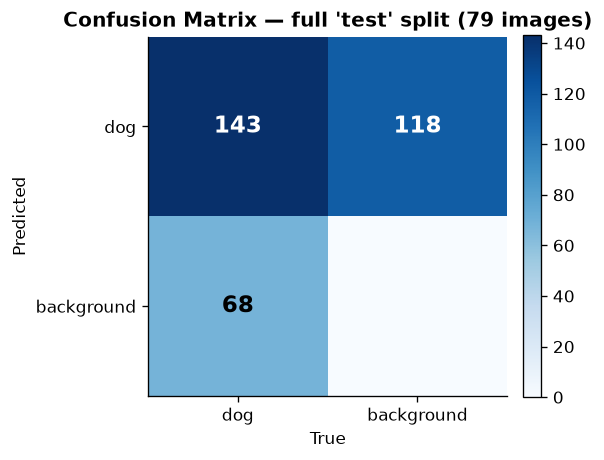

In [15]:
# Confusion matrix aggregated over the FULL evaluated split (unlike Section 5's
# plot, which YOLO generates only from the validation split at training time)
cm = np.array([[tp_total, fp_total],
               [fn_total, np.nan]])  # background→background is not defined

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(np.nan_to_num(cm), cmap="Blues", vmin=0)
ax.set_xticks([0, 1]); ax.set_xticklabels(["dog", "background"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["dog", "background"])
ax.set_xlabel("True"); ax.set_ylabel("Predicted")
ax.set_title(f"Confusion Matrix — full '{eval_split}' split ({len(per_image)} images)",
             fontweight="bold")
for i in range(2):
    for j in range(2):
        if np.isnan(cm[i, j]):
            continue
        ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=14,
                fontweight="bold",
                color="white" if cm[i, j] > np.nanmax(cm) / 2 else "black")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(RUN_DIR / "confusion_matrix_full_split.png", dpi=150, bbox_inches="tight")
plt.show()

**What these show:** The bar chart aggregates TP/FP/FN across *every* image in the
evaluated split (not just one, unlike Section 5) into total counts and the derived
Precision/Recall/F1. The matrix above is the same three numbers laid out as a proper
dog/background confusion matrix — directly comparable to Section 5's plot, but far
more representative since it's computed over the whole split instead of a single
frame.

---
## 8. Example Predictions on Images

- **Green** = Ground truth (manually annotated)
- **Red** = Model prediction (with confidence)

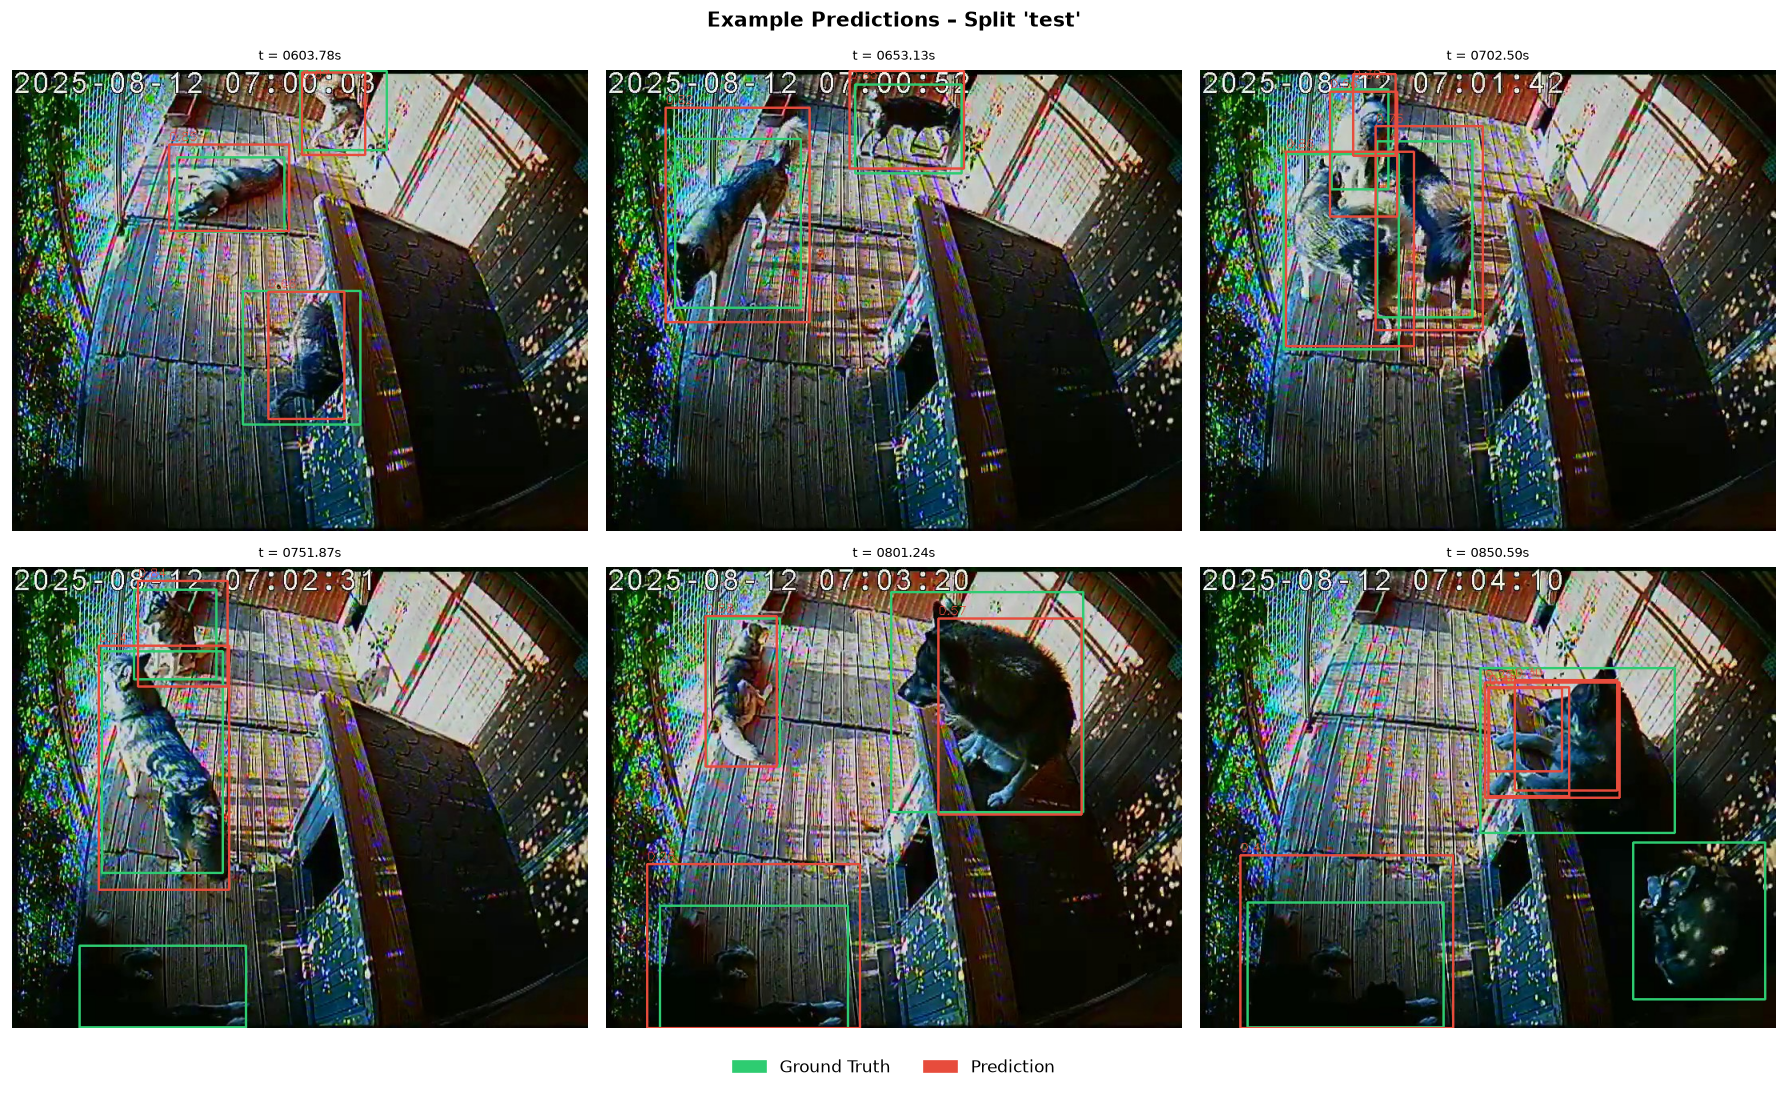

In [16]:
test_images = sorted(eval_img_dir.glob("*.jpg"))
n_show = min(6, len(test_images))

if n_show == 0:
    print("No images found.")
else:
    # Evenly distribute across the split
    step = max(1, len(test_images) // n_show)
    sample = [test_images[i * step] for i in range(n_show)]

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()
    fig.suptitle(f"Example Predictions – Split '{eval_split}'", fontsize=12, fontweight="bold")

    gt_patch   = mpatches.Patch(color="#2ecc71", label="Ground Truth")
    pred_patch = mpatches.Patch(color="#e74c3c", label="Prediction")

    for ax, img_path in zip(axes[:n_show], sample):
        lbl_path = eval_lbl_dir / (img_path.stem + ".txt")

        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        # Ground truth (green)
        if lbl_path.exists():
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        cx, cy, bw, bh = [float(x) for x in parts[1:]]
                        x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                        x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                        cv2.rectangle(img, (x1, y1), (x2, y2), (46, 204, 113), 2)

        # Prediction (red)
        result = model(str(img_path), verbose=False)[0]
        for box in result.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
            conf = float(box.conf[0])
            cv2.rectangle(img, (x1, y1), (x2, y2), (231, 76, 60), 2)
            cv2.putText(img, f"{conf:.2f}", (x1, max(y1 - 5, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (231, 76, 60), 1)

        ax.imshow(img)
        # Timestamp from filename
        time_match = img_path.stem.split("_time_")
        time_label = f"t = {time_match[-1]}s" if len(time_match) > 1 else img_path.stem[-25:]
        ax.set_title(time_label, fontsize=8)
        ax.axis("off")

    for ax in axes[n_show:]:
        ax.axis("off")

    fig.legend(handles=[gt_patch, pred_patch], loc="lower center",
               ncol=2, fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout()
    plt.savefig(RUN_DIR / "example_predictions.png", dpi=150, bbox_inches="tight")
    plt.show()

**What this shows:** Ground truth (green) vs. model predictions (red, with
confidence) on a handful of frames sampled evenly across the split. Useful for a
qualitative gut-check — look for patterns in the mistakes (e.g. dogs missed when
overlapping, low confidence in poor lighting) that the aggregate metrics above don't
reveal.

---
## 9. Summary

In [17]:
best_map50   = df["metrics/mAP50(B)"].max()
best_ep      = int(df.loc[best_idx, "epoch"])
best_prec    = df["metrics/precision(B)"].iloc[best_idx]
best_recall  = df["metrics/recall(B)"].iloc[best_idx]

print("=" * 55)
print("  SUMMARY")
print("=" * 55)
print(f"  Trained for           : {len(df)} epochs")
print(f"  Best model             : epoch {best_ep}")
print(f"  Precision (best)       : {best_prec:.4f}")
print(f"  Recall    (best)       : {best_recall:.4f}")
print(f"  mAP@50    (best)       : {best_map50:.4f}")
print()
print(f"  TP / FP / FN ({eval_split})    : {tp_total} / {fp_total} / {fn_total}")
print(f"  F1-Score ({eval_split})        : {f1:.4f}")
print()
print(f"  Overfitting            : {'yes – best.pt contains the best model' if final_gap > 0.3 else 'no / minor'}")
print()
print(f"  Saved model            : {BEST_WEIGHTS}")
print(f"  Intermediate checkpoints: {list((RUN_DIR / 'weights').glob('epoch*.pt'))}")

  SUMMARY
  Trained for           : 50 epochs
  Best model             : epoch 41
  Precision (best)       : 0.9868
  Recall    (best)       : 0.9794
  mAP@50    (best)       : 0.9936

  TP / FP / FN (test)    : 143 / 118 / 68
  F1-Score (test)        : 0.6059

  Overfitting            : yes – best.pt contains the best model

  Saved model            : runs/detect/dogs_medium/weights/best.pt
  Intermediate checkpoints: [PosixPath('runs/detect/dogs_medium/weights/epoch0.pt'), PosixPath('runs/detect/dogs_medium/weights/epoch10.pt'), PosixPath('runs/detect/dogs_medium/weights/epoch20.pt'), PosixPath('runs/detect/dogs_medium/weights/epoch30.pt'), PosixPath('runs/detect/dogs_medium/weights/epoch40.pt')]
